# P2 프로젝트: 정기예금 가입

포르투갈 은행의 전화 마케팅 데이터를 이용하여 고객의 정기예금 가입 여부를 예측한다.

> **전화 통화를 시작하기 전에, 어떤 고객이 정기예금에 가입할 가능성이 높은지 예측할 수 있는가?**

제공된 코드를 출발점으로 이진 분류 프로젝트의 전체 흐름을 수행한다. AI의 도움을 받아도 되지만, **누수 판단, 평가 지표 해석, 결정 임곗값 선택, 최종 결론은 직접 판단한다.**

**코드 실행**

[(구글 코랩) P2 프로젝트: 정기예금 가입](https://colab.research.google.com/github/codingalzi/code-workout-ml/blob/master/p2_project_bank_marketing.ipynb)에서 코드를 실행할 수 있다.

**프로젝트 진행 원칙**

1. **최종 테스트셋은 모델과 임곗값 선택이 끝날 때까지 확인하지 않는다.**
2. **예측 시점에 알 수 없는 정보는 입력 특성에서 제외한다.**
3. **정확도 하나만으로 분류 모델을 판단하지 않는다.**
4. **결정 임곗값은 검증 데이터에서 선택하고 테스트 데이터에서 다시 조정하지 않는다.**
5. **AI는 도구로 활용하되 중요한 판단에는 자신의 근거를 남긴다.**

**환경설정**

In [1]:
import sys
import sklearn
from packaging.version import Version

assert sys.version_info >= (3, 10)
assert Version(sklearn.__version__) >= Version("1.6.1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", size=12)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=12)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

## 1단계 — 문제 정의, 데이터 이해, EDA

### 문제를 데이터의 언어로 바꾼다

이번 프로젝트에서는 **현재 전화 통화가 시작되기 직전**을 예측 시점으로 정한다.

- **샘플**: 한 고객의 은행 마케팅 기록
- **타깃**: 정기예금 가입 여부 `y`
- **양성 클래스**: 가입 `yes`
- **음성 클래스**: 미가입 `no`
- **문제 유형**: 두 클래스 중 하나를 예측하는 **이진 분류**
- **예측 시점**: 현재 전화 통화를 시작하기 직전
- **분석 목적**: 가입 가능성이 높은 고객을 구분하고, 목적에 맞는 결정 임곗값을 선택한다.

예측 시점을 먼저 정해야 **어떤 변수를 실제 예측에 사용할 수 있는지** 판단할 수 있다.

### 프로젝트 기록 ① — 분석 설계

다음을 자신의 말로 작성한다.

- **분석 목적**: 고객과의 전화통화 이전에, 전화 마케팅 데이터(통화 전에 알 수 있는)를 이용하여 고객의 정기예금 가입여부를 예측한다.
- **타깃과 양성 클래스**: 타깃: 정기예금 가입 여부 , 양성 클래스: 가입(yes)
- **이진 분류라고 판단한 이유**: 이진 분류는 두 클래스 중 하나를 선택하여 결과를 예측하는 문제이며, 이번 프로젝트에서는 정기예금의 가입(yes) / 미가입(no) 의 두가지 클래스 중 하나를 예측하는 문제이기 때문에 이진 분류라고 판단함.
- **예측 시점**: 마케터와 고객이 전화 통화를 시작하기 직전의 시점
- **예측 결과를 실제로 어떻게 활용할 수 있는가?**: 예측 결과를 통해 가입 가능성이 높은 고객을 타겟으로 마케팅을 실시해 제한된 자원에서의 마케팅 인력과 시간을 효율적으로 배분할 수 있음
또한 추후의 예측 결과를 이용한 고객 마케팅 데이터를 기존의 데이터와 비교하여 효율 개선 여부을 확인해 다른 업무에도 데이터를 활용한 업무 향상을 기대할 수 있음

### 데이터를 불러와 구조를 확인한다

UCI Bank Marketing의 `bank-full.csv`에 해당하는 데이터를 사용한다.  
45,211개의 사례와 16개의 입력 특성이 포함된 버전이다.

In [2]:
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"

with urlopen(url) as response:
    zip_data = BytesIO(response.read())

with ZipFile(zip_data) as z:
    df = pd.read_csv(
        z.open("bank-full.csv"),
        sep=";"
    )

df["y"] = (df["y"] == "yes").astype(int)

print("데이터 크기:", df.shape)
df.head()

데이터 크기: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


필요한 열이 모두 들어왔는지 확인한다.

In [3]:
required_cols = {
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "duration", "campaign", "pdays",
    "previous", "poutcome", "y"
}

missing_cols = sorted(required_cols - set(df.columns))

if missing_cols:
    raise ValueError(f"필요한 열이 없습니다: {missing_cols}")

print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
df.info()

`unknown`은 이 데이터에서 하나의 범주로 기록되어 있다.  
이번 프로젝트에서는 임의로 다른 값으로 바꾸지 않고 **하나의 범주로 그대로 사용**한다.

### 최종 테스트셋을 먼저 보존한다

전체 데이터의 20%를 **최종 테스트셋**으로 분리한다.

타깃 비율이 크게 달라지지 않도록 `stratify`를 사용한다.  
테스트셋의 타깃 분포와 모델 성능은 최종 평가 전까지 확인하지 않는다.

In [4]:
from sklearn.model_selection import train_test_split

dev_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["y"],
    random_state=42
)

print("개발 데이터:", dev_df.shape)
print("최종 테스트 데이터:", test_df.shape)

개발 데이터: (36168, 17)
최종 테스트 데이터: (9043, 17)


### 개발 데이터에서 클래스 비율을 확인한다

정확도만으로 모델을 평가해도 되는지 판단하려면 먼저 클래스 비율을 확인해야 한다.

In [5]:
target_summary = pd.DataFrame({
    "count": dev_df["y"].value_counts().sort_index(),
    "rate": dev_df["y"].value_counts(normalize=True).sort_index()
})

target_summary.index = ["no", "yes"]
target_summary

,count,rate
no,31937,0.883018
yes,4231,0.116982


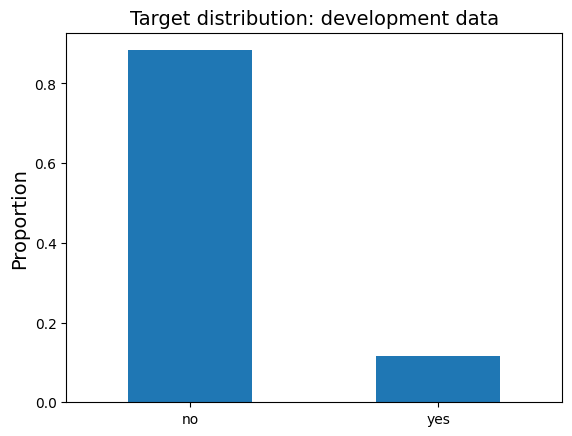

In [6]:
target_summary["rate"].plot(kind="bar")

plt.ylabel("Proportion")
plt.title("Target distribution: development data")
plt.xticks(rotation=0)
plt.show()

가입 고객이 전체에서 소수라면, 대부분을 `no`로 예측하는 모델도 높은 정확도를 얻을 수 있다.

따라서 이번 프로젝트에서는 **정확도뿐 아니라 정밀도, 재현율, ROC-AUC를 함께 본다.**

### 모델링 전에 데이터 누수를 점검한다

`duration`은 **마지막 전화 통화가 몇 초 동안 지속되었는지**를 나타낸다.

이번 프로젝트의 예측 시점은 **전화 통화를 시작하기 직전**이다.  
따라서 그 시점에는 통화가 얼마나 오래 지속될지 알 수 없다.

> **예측 시점에 알 수 없는 `duration`을 입력 특성으로 사용하면 데이터 누수가 발생한다.**

`duration`은 가입 여부와 강한 관련이 있을 수 있으므로 모델 성능을 크게 높일 수 있다. 하지만 실제 예측에서는 사용할 수 없기 때문에 최종 모델에서는 제외한다.

In [7]:
# 개발 데이터에서만 duration과 가입 여부의 관계를 확인한다.
dev_df.groupby("y")["duration"].agg(
    ["count", "mean", "median"]
).rename(index={0: "no", 1: "yes"})

,count,mean,median
y,,,
no,31937,221.085982,164.0
yes,4231,540.972820,426.0


`duration`이 가입 여부를 잘 구분한다고 해서 좋은 입력 변수라는 뜻은 아니다.

중요한 질문은 다음이다.

> **모델이 실제 예측을 하는 순간에 이 정보를 알 수 있는가?**
: duration은 전화 통화 후에 알 수 있는 데이터이므로 통화 직전 시점에서 예측을 하는 모델은 이 정보를 알 수 없고, 이 데이터를 사용할 수 없다 따라서 입력 변수로 사용하면 데이터 누수가 발생한다.

이번 프로젝트에서는 `duration`을 **누수 확인용으로만 살펴보고 실제 모델의 입력에서는 제외한다.**

### 프로젝트 기록 ② — 입력 변수와 데이터 누수

다음을 작성한다.

- `duration`이 가입 여부 예측에 유용해 보일 수 있는 이유: 고객과의 마지막 통화 시간의 길이 여부를 통해 가입여부를 판단 하는데 유용할 것이라고 판단한다 통화 시간이 긴 고객은 상품에 관심이 있거나 가입절차를 진행했을 가능성이 있으므로 통화 시간이 가입 여부 예측에 유용할 수 있다고 판단한다.
- 그래도 `duration`을 제외해야 하는 이유: duration은 전화 통화 이후에 알 수 있는 데이터 이므로 통화 직전 시점에서 예측을 해야하는 모델은 이 정보를 사전에 알 수 없고 데이터를 사용할 수 없다 따라서 이를 입력 변수로 사용하면 데이터 누수가 발생한다.
- **예측 시점**을 다르게 정의하면 `duration`을 사용할 수도 있는가? 그 이유는?: 예측 시점을 고객과의 통화 이후로 정의한다면 duration을 사용할 수 있을거라고 판단함 duration은 고객과의 마지막 통화 시간 데이터이기 때문에 통화 이후에 만들어지는 데이터임 따라서 예측 시점을 통화 이후로 정의한다면 데이터를 사용할 수 있다고 판단한다.
- 다른 변수들도 예측 시점에 사용할 수 있는지 어떻게 확인해야 하는가?: 각 변수의 의미와 기록 시점등을 확인하여 통화 시작 직전 자료인지 판단한다.

### 개발 데이터만 탐색한다

최종 테스트셋은 아직 사용하지 않는다.

먼저 직업별 가입률을 확인한다.

In [8]:
job_rate = (
    dev_df.groupby("job", dropna=False)["y"]
          .agg(["mean", "count"])
          .sort_values("mean", ascending=False)
)

job_rate

,mean,count
job,,
student,0.288918,758
retired,0.229581,1812
unemployed,0.154297,1024
management,0.138597,7511
admin.,0.122917,4141
unknown,0.119658,234
self-employed,0.114240,1243
technician,0.109262,6068
services,0.089008,3348


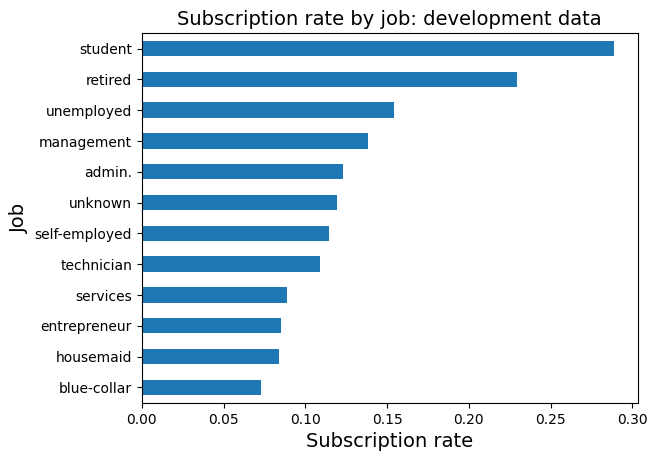

In [9]:
job_rate["mean"].sort_values().plot(kind="barh")

plt.xlabel("Subscription rate")
plt.ylabel("Job")
plt.title("Subscription rate by job: development data")
plt.show()

이전 마케팅 캠페인의 결과(`poutcome`)에 따라서도 가입률이 다른지 확인한다.

In [10]:
poutcome_rate = (
    dev_df.groupby("poutcome", dropna=False)["y"]
          .agg(["mean", "count"])
          .sort_values("mean", ascending=False)
)

poutcome_rate

,mean,count
poutcome,,
success,0.646473,1205
other,0.164983,1485
failure,0.122911,3889
unknown,0.092230,29589


### 나만의 EDA 질문 하나를 만든다

다음 변수 중 하나 이상을 사용하여 질문을 만든다.

`age`, `education`, `balance`, `housing`, `loan`, `month`, `campaign`, `pdays`, `previous`

예:

- 교육 수준에 따라 가입률이 다른가?
- 주택 대출 보유 여부와 가입률은 관련이 있는가?
- 이전 접촉 횟수와 가입 여부는 어떤 관계가 있는가?

**나의 질문**

> 작성:
1. 고객의 나이에 따라 가입률이 다른가?
2. 교육 수준에 따라 가입률이 다른가?
3. 신용 채무 불이행 여부는 가입률과 관련이 있는가?

,count,subscribers,subscription_rate,subscription_rate_pct
age_group,,,,
30세 미만,4270,749,0.18,17.54
30~39세,14481,1534,0.11,10.59
40~49세,9323,854,0.09,9.16
50~59세,6647,606,0.09,9.12
60세 이상,1447,488,0.34,33.72


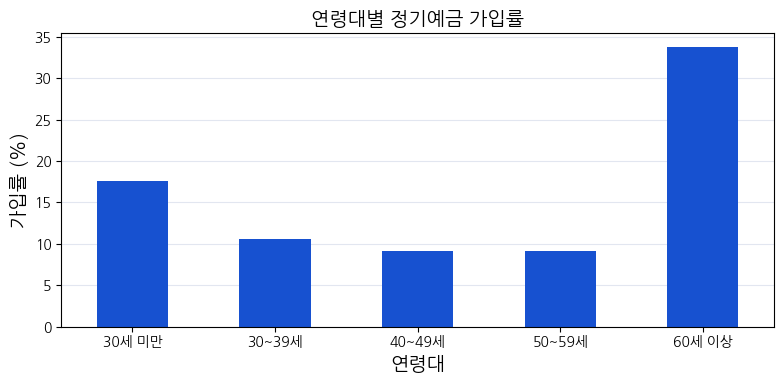

,count,subscribers,subscription_rate,subscription_rate_pct
education,,,,
primary,5531,477,0.09,8.62
secondary,18561,1981,0.11,10.67
tertiary,10594,1577,0.15,14.89
unknown,1482,196,0.13,13.23


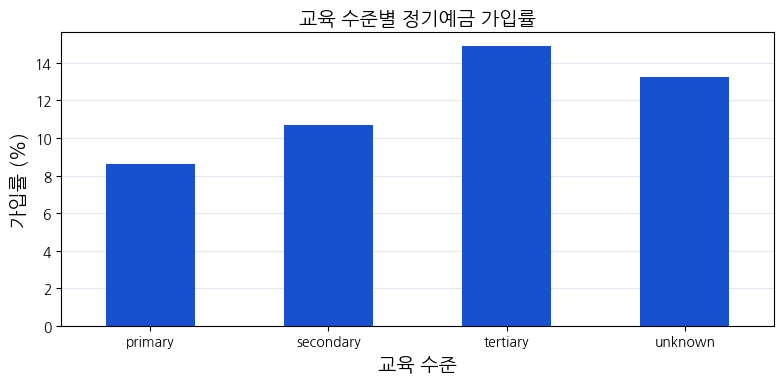

,count,subscribers,subscription_rate,subscription_rate_pct
default,,,,
no,35521,4193,0.12,11.80
yes,647,38,0.06,5.87


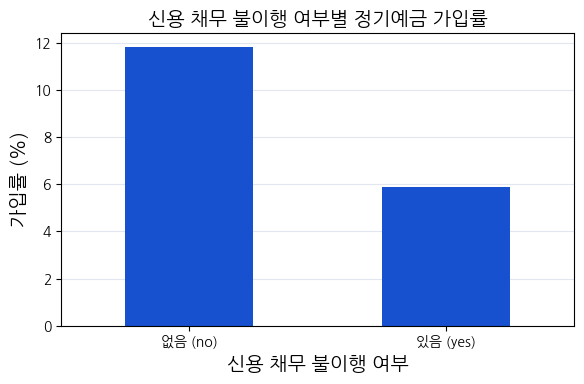

In [12]:
# TODO
# 위에서 정한 EDA 질문을 확인하는 코드를 작성한다.

# 그래프에 한글을 표시하기 위한 설정
%pip -q install koreanize-matplotlib
import koreanize_matplotlib

# 가입률 계산 전에 y가 0과 1인지 확인
assert dev_df["y"].notna().all(), "y에 결측값이 있습니다."
assert dev_df["y"].isin([0, 1]).all(), "y를 가입 1, 미가입 0으로 먼저 변환하세요."

# 개발 데이터에서 필요한 열만 복사
age_data = dev_df[["age", "y"]].copy()


####################################################

# 1. 고객의 나이에 따라 가입률이 다른가?

# 연령대 구분: 왼쪽 경계 포함, 오른쪽 경계 제외
age_data["age_group"] = pd.cut(
    age_data["age"],
    bins=[0, 30, 40, 50, 60, float("inf")],
    labels=["30세 미만", "30~39세", "40~49세", "50~59세", "60세 이상"],
    right=False
)

# 연령대별 표본 수, 가입자 수, 가입률 계산
age_summary = (
    age_data.groupby("age_group", observed=False)["y"]
    .agg(count="count", subscribers="sum", subscription_rate="mean")
)

age_summary["subscription_rate_pct"] = (
    age_summary["subscription_rate"] * 100
)

display(age_summary.round(2))

# 연령대별 가입률 그래프
ax = age_summary["subscription_rate_pct"].plot(
    kind="bar",
    figsize=(8, 4),
    color="#1751D0",
    rot=0
)

ax.set_title("연령대별 정기예금 가입률")
ax.set_xlabel("연령대")
ax.set_ylabel("가입률 (%)")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#E2E6F0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


####################################################

# 2. 교육 수준에 따라 가입률이 다른가?


# 교육 수준을 표시할 순서
education_order = ["primary", "secondary", "tertiary", "unknown"]

# 개발 데이터에서 교육 수준별 집계
education_summary = (
    dev_df.groupby("education")["y"]
    .agg(count="count", subscribers="sum", subscription_rate="mean")
    .reindex(education_order)
)

education_summary["subscription_rate_pct"] = (
    education_summary["subscription_rate"] * 100
)

display(education_summary.round(2))

# 교육 수준별 가입률 그래프
ax = education_summary["subscription_rate_pct"].plot(
    kind="bar",
    figsize=(8, 4),
    color="#1751D0",
    rot=0
)

ax.set_title("교육 수준별 정기예금 가입률")
ax.set_xlabel("교육 수준")
ax.set_ylabel("가입률 (%)")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#E2E6F0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


####################################################

# 3. 신용 채무 불이행 여부는 가입률과 관련이 있는가?

# 개발 데이터에서 채무 불이행 여부별 집계
default_summary = (
    dev_df.groupby("default")["y"]
    .agg(count="count", subscribers="sum", subscription_rate="mean")
    .reindex(["no", "yes"])
)

default_summary["subscription_rate_pct"] = (
    default_summary["subscription_rate"] * 100
)

display(default_summary.round(2))

# 채무 불이행 여부별 가입률 그래프
ax = default_summary["subscription_rate_pct"].plot(
    kind="bar",
    figsize=(6, 4),
    color="#1751D0",
    rot=0
)

ax.set_title("신용 채무 불이행 여부별 정기예금 가입률")
ax.set_xlabel("신용 채무 불이행 여부")
ax.set_ylabel("가입률 (%)")
ax.set_xticklabels(["없음 (no)", "있음 (yes)"])
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#E2E6F0")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### AI 체크포인트 ① — EDA

AI에게 자신의 질문과 사용할 변수를 알려주고 분석 코드를 제안받아도 된다.

실행 전에는 다음을 직접 확인한다.

- **개발 데이터만 사용하는가?** : dev_df만 사용했고 최종 테스트 데이터인 test_df는 사용하지 않았다.
- 질문에 맞는 변수와 그래프인가? : age, education, default 별로 가입 여부(y)의 평균을 계산했다 이에 따라 가입률을 비교하는 막대그래프가 질문에 적절하다고 생각했고 표본의 수도 확인하도록 했다.
- 범주형과 수치형의 의미를 잘못 해석하지 않았는가? : age 데이터는 수치형 특성이므로 연령대별 가입률을 비교하기 위해 범주로 묶어서 사용하였다 교육 수준과 채무 불이행 여부는 범주별로 비교하였다
- 관찰된 관계를 인과관계로 단정하지 않았는가? : 해당 코드를 통해 가입률 차이만 보여주고 있으며 이를 통해 인과관계로 단정하지 않았다.

### 프로젝트 기록 ③ — EDA에서 발견한 것

세 가지를 기록한다.

- **발견 1**: 나이 별 가입률을 확인해본 결과, 60세 이상의 연령대의 가입률이 제일 높았으며, 그 뒤로는 30세 미만의 가입률이 높았다 30-59세 사이의 가입률은 10% 안팎으로 저조한 모습을 보이고 있다. 이를 통해 60세 이상 연령층과 30세 미만 연령층, 그리고 나머지 연령대별 가입률에 차이가 있으므로 나이정보가 예측에 유용할 수 있다고 판단한다.  / 모델링과의 연결: 30세 미만, 30~59세, 60세 이상 집단의 가입률에 차이가 있으므로, 나이를 이러한 연령대 범주로 나누어 입력변수로 활용하는 방법이 가입여부 예측에 도움이 될 수 있다고 판단한다.
- **발견 2**: 교육 수준 별 가입률을 확인해본 결과, tertiary(고등교육/대학교육)의 가입률이 제일 높았으며 그 뒤로 secondary(중등교육), primary(초등교육)순으로 높은 가입률을 보이고 있다. 이를 통해서 교육수준에 따른 가입률에 차이가 있으므로 교육 수준 정보가 예측에 유용하다고 판단한다. / 모델링과의 연결: 교육 수준을 primary, secondary, tertiary, unknown 범주로 구분하여 입력변수로 활용하는 것이 가입여부 예측에 도움이 될 수 있다고 판단한다.
- **발견 3**: 신용 채무 불이행 여부 별 가입률을 확인해본 결과, 신용 채무 불이행이 없는 고객(no)가 신용 채무 불이행 고객(yes) 보다 더 높은 가입률을 보이고 있다. 이를 통해 채무 불이행 여부에 따른 가입률 차이가 보이므로 신용 채무 불이행 여부 정보가 예측에 유용할 수 있다고 판단한다. / 모델링과의 연결: 신용 채무 불이행 여부를 있음(yes)과 없음(no)으로 구분하여 범주형 입력변수로 활용하는 것이 가입 여부 예측에 도움이 될 수 있다고 판단한다.

> 단순히 “가입률이 높다/낮다”에서 끝내지 말고, 어떤 정보가 예측에 유용할 수 있는지 설명한다.

### 입력 특성과 타깃을 확정한다

이번 프로젝트의 기본 분석에서는 `duration`을 제외하고 나머지 변수를 사용한다.

범주형 변수는 **원-핫 인코딩**, 수치형 변수는 **표준화**한다.

`education`에는 순서가 있어 보이지만 기본 분석에서는 `primary → secondary → tertiary` 사이의 간격이 동일하다고 가정하지 않기 위해 원-핫 인코딩한다.

`day` 역시 숫자로 저장되어 있지만 날짜의 순서를 나타내는 범주로 보고 원-핫 인코딩한다.

In [13]:
target = "y"

exclude_cols = [
    target,
    "duration"  # 예측 시점 이후에 알 수 있는 누수 변수
]

feature_cols = [
    c for c in df.columns
    if c not in exclude_cols
]

categorical_cols = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "day",
    "month", "poutcome"
]

numeric_cols = [
    c for c in feature_cols
    if c not in categorical_cols
]

print("타깃:", target)
print("사용 특성:", feature_cols)
print("범주형:", categorical_cols)
print("수치형:", numeric_cols)

타깃: y
사용 특성: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
범주형: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'day', 'month', 'poutcome']
수치형: ['age', 'balance', 'campaign', 'pdays', 'previous']


### 1단계 마무리 체크

다음을 설명할 수 있는지 확인한다.

- 예측 대상과 이진 분류 문제의 의미 : 예측대상: 통화 직전 고객의 정기 예금 가입 여부 / 이진 분류 문제는 두 클래스 중 하나를 선택하여 결과를 예측하는 문제이다.
- 예측 시점이 중요한 이유 : 예측 시점에 따라 사용할 수 있는 정보가 달라지기 때문이다 duration 데이터는 통화 후에 알 수 있는 데이터이므로 통화 직전의 가입 여부를 예측하는 모델에서는 사용할 수 없다.
- `duration`이 데이터 누수인 이유 : duration 데이터는 통화 직후에 알 수 있는 데이터이므로 통화 직전 가입 여부를 기반으로 예측할때 그 시점에 알 수 없는 데이터이기 때문에 데이터 누수가 발생하기 때문이다.
- 양성 클래스 비율이 모델 평가에 미치는 영향 : 양성 클래스 비율이 낮다면 정확도만으로 모델을 평가하기 어려워진다 즉 미가입 고객만 예측해도 정확도는 높게 나타날 수 있기 때문에 재현율과 정밀도 등의 다른 지표도 함께 확인해야 한다.
- 범주형 변수와 수치형 변수를 다르게 처리하는 이유 : 범주형 변수는 종류를 구분하는 정보이기 때문에 원-핫 인코딩을 통해 범주에 크기나 간격을 부여하지 않도록 한다 수치형 변수는 각자 단위나 크기가 다르기 때문에 표준화를 통해 이를 해결한다.

## 2단계 — 전처리, 모델 훈련, 검증과 임곗값 선택

### 개발 데이터를 학습용과 검증용으로 다시 나눈다

최종 테스트셋은 사용할 수 없으므로 개발 데이터 안에서 다시 나눈다.

- 전체 데이터의 약 60% → **학습용**
- 전체 데이터의 약 20% → **검증용**
- 앞에서 보존한 약 20% → **최종 테스트용**

학습용과 검증용도 양성 클래스 비율이 유지되도록 나눈다.

In [14]:
train_df, val_df = train_test_split(
    dev_df,
    test_size=0.25,
    stratify=dev_df[target],
    random_state=42
)

X_train = train_df[feature_cols]
y_train = train_df[target]

X_val = val_df[feature_cols]
y_val = val_df[target]

print("학습용:", X_train.shape)
print("검증용:", X_val.shape)

학습용: (27126, 15)
검증용: (9042, 15)


### 전처리 과정을 하나의 파이프라인으로 묶는다

- **수치형 변수** → 결측치 처리 + 표준화
- **범주형 변수** → 결측치 처리 + 원-핫 인코딩

`Pipeline`을 사용하면 전처리도 학습 데이터에서만 `fit()`되고, 검증·테스트 데이터에는 이미 학습된 변환만 적용된다.

In [15]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(numeric_features, categorical_features):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])

preprocess = build_preprocessor(
    numeric_cols,
    categorical_cols
)

### 기준선과 로지스틱 회귀를 비교한다

`DummyClassifier`는 입력 특성을 사용하지 않고 단순한 규칙으로 예측한다.  
이번에는 가장 많은 클래스인 `no`를 항상 예측하는 기준선으로 사용한다.

로지스틱 회귀가 기준선보다 어떤 점에서 나아지는지 확인한다.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def make_pipeline(estimator, prep=preprocess):
    return Pipeline([
        ("prep", clone(prep)),
        ("model", estimator)
    ])

models = {
    "Baseline(most frequent)": make_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),
    "LogisticRegression": make_pipeline(
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
}

### 같은 기준으로 검증한다

분류 모델은 하나의 숫자로만 평가하지 않는다.

- **Accuracy**: 전체에서 맞게 분류한 비율
- **Precision**: 가입한다고 예측한 고객 중 실제 가입한 비율
- **Recall**: 실제 가입 고객 중 모델이 찾아낸 비율
- **ROC-AUC**: 여러 임곗값에서 양성과 음성을 구분하는 능력을 요약한 값

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

def classification_scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "FP": fp,
        "FN": fn
    }

In [18]:
validation_rows = []

for name, model in models.items():
    model.fit(X_train, y_train)

    proba = model.predict_proba(X_val)[:, 1]
    scores = classification_scores(
        y_val,
        proba,
        threshold=0.5
    )

    validation_rows.append({
        "Model": name,
        **scores
    })

validation_results = (
    pd.DataFrame(validation_rows)
      .set_index("Model")
)

validation_results

,Accuracy,Precision,Recall,ROC-AUC,FP,FN
Model,,,,,,
Baseline(most frequent),0.882990,0.000000,0.000000,0.50000,0,1058
LogisticRegression,0.895045,0.679868,0.194707,0.77748,97,852


### 정확도가 높은 것만으로 충분한가?

기준선은 대부분의 고객을 `no`라고 예측하기 때문에 정확도가 높게 보일 수 있다.

그러나 가입 고객을 전혀 찾아내지 못한다면 실제 마케팅 의사결정에는 도움이 되지 않는다.

**정확도, 정밀도, 재현율을 함께 해석한다.**

### 누수가 성능을 얼마나 왜곡하는지 확인한다

이번에는 경고를 위한 비교 실험으로 `duration`을 포함한 로지스틱 회귀를 한 번만 만들어 본다.

> 이 모델은 **실제 최종 후보가 아니다.**

검증 성능이 좋아지더라도, 예측 시점에 사용할 수 없는 정보를 이용했기 때문에 실제 문제를 해결하는 모델로 사용할 수 없다.

In [19]:
leaky_feature_cols = feature_cols + ["duration"]

leaky_numeric_cols = numeric_cols + ["duration"]

leaky_preprocess = build_preprocessor(
    leaky_numeric_cols,
    categorical_cols
)

leaky_model = make_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    prep=leaky_preprocess
)

leaky_model.fit(
    train_df[leaky_feature_cols],
    y_train
)

leaky_val_proba = leaky_model.predict_proba(
    val_df[leaky_feature_cols]
)[:, 1]

clean_model = models["LogisticRegression"]
clean_val_proba = clean_model.predict_proba(X_val)[:, 1]

leakage_comparison = pd.DataFrame({
    "No leakage": classification_scores(
        y_val, clean_val_proba, 0.5
    ),
    "With duration (leakage)": classification_scores(
        y_val, leaky_val_proba, 0.5
    )
}).T

leakage_comparison

,Accuracy,Precision,Recall,ROC-AUC,FP,FN
No leakage,0.895045,0.679868,0.194707,0.77748,97.0,852.0
With duration (leakage),0.902123,0.650960,0.352552,0.91101,200.0,685.0


### 프로젝트 기록 ④ — 모델과 누수 결과 해석

다음을 작성한다.

- 기준선의 정확도가 높게 보이는 이유: 양성 클래스의 비율이 낮기 때문에 모든 예측을 (no)로 해도 정확도가 높을 수 있다.
- 로지스틱 회귀가 기준선보다 개선된 점: 로지스틱 회귀가 기준선보다 정확도가 약 88.3% -> 89.5%로 높아졌고, ROC-AUC도 0.5 -> 0.777로 상승했다 또한 기준선은 가입 고객을 찾지 못했지만 로지스틱 회귀는 실제 가입 고객의 약 19.5%를 찾아내었다
- `duration`을 포함했을 때 성능이 어떻게 달라졌는가?: duration을 사용했을때 정확도는 89.5% 에서 90.2%로 높아졌고, ROC_AUC도 0.777 -> 0.911로 상승했다 재현율은 35.3%로 높아졌지만 정밀도는 65.1%로 낮아졌다 실제 가입 고객을 더 많이 찾아내어 852명 -> 685명(FN)으로 줄었지만 미가입 고객을 가입한다고 잘못 예측한 FP는 97명 -> 200명으로 늘었다.
- 성능이 더 좋아졌더라도 누수 모델을 사용하면 안 되는 이유: duration은 예측 시점에서 사용할 수 없는 정보이기 때문에 이를 포함해서 예측하는 누수 모델을 사용하면 안된다고 판단한다.

### 결정 임곗값에 따라 정밀도와 재현율이 달라진다

이제 **누수가 없는 로지스틱 회귀**만 사용한다.

기본 임곗값 `0.5`를 그대로 사용할 필요는 없다.  
검증 데이터에서 정밀도와 재현율의 변화를 확인한 뒤 프로젝트 목적에 맞는 값을 선택한다.

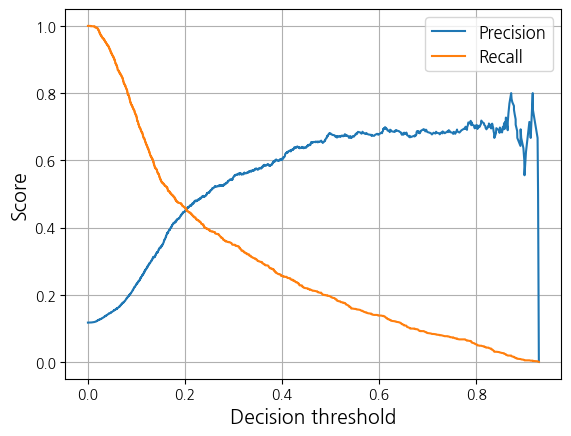

In [20]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    clean_val_proba
)

plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")

plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

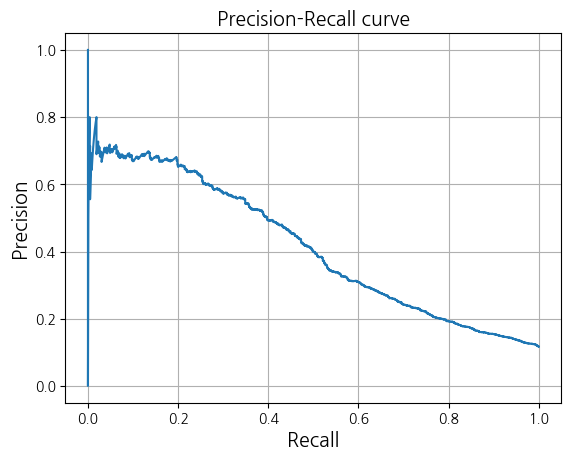

In [21]:
plt.plot(recalls, precisions)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve")
plt.grid()
plt.show()

여러 임곗값을 직접 비교한다. 필요하면 후보 값을 수정하거나 추가한다.

In [22]:
threshold_candidates = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.60
]

threshold_rows = []

for threshold in threshold_candidates:
    scores = classification_scores(
        y_val,
        clean_val_proba,
        threshold
    )

    pred = (
        clean_val_proba >= threshold
    ).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": scores["Accuracy"],
        "Precision": scores["Precision"],
        "Recall": scores["Recall"],
        "Predicted positive rate": pred.mean(),
        "FP": scores["FP"],
        "FN": scores["FN"]
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results

,Threshold,Accuracy,Precision,Recall,Predicted positive rate,FP,FN
0,0.10,0.682150,0.230244,0.732514,0.372263,2591,283
1,0.15,0.823712,0.340855,0.542533,0.186242,1110,484
2,0.20,0.870714,0.448753,0.459357,0.119774,597,572
3,0.25,0.883875,0.504854,0.393195,0.091130,408,642
4,0.30,0.890400,0.549925,0.348771,0.074209,302,689
5,0.35,0.892059,0.574007,0.300567,0.061270,236,740
6,0.40,0.893276,0.603563,0.256144,0.049657,178,787
7,0.45,0.894271,0.640884,0.219282,0.040035,130,826
8,0.50,0.895045,0.679868,0.194707,0.033510,97,852
9,0.60,0.891506,0.679070,0.137996,0.023778,69,912


### ROC 곡선과 AUC를 확인한다

ROC-AUC는 특정 임곗값 하나가 아니라 여러 임곗값에서의 구분 능력을 요약한다.

임곗값 선택에는 정밀도와 재현율을 함께 사용한다.

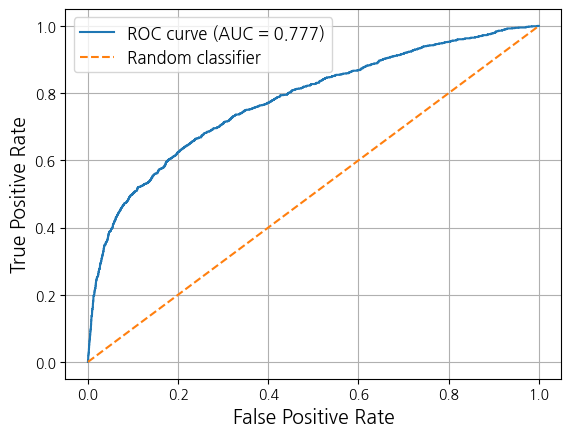

ROC-AUC: 0.7774801730114294


In [23]:
from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(
    y_val,
    clean_val_proba
)

roc_auc = roc_auc_score(
    y_val,
    clean_val_proba
)

plt.plot(
    fpr,
    tpr,
    label=f"ROC curve (AUC = {roc_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", roc_auc)

### 프로젝트 기록 ⑤ — 결정 임곗값 선택

먼저 어떤 오류가 더 중요한지 생각한다.

- **FP**: 가입할 것이라고 예측했지만 실제로는 가입하지 않은 고객
- **FN**: 실제 가입 고객인데 모델이 가입하지 않을 것으로 예측한 경우

다음을 기록한다.

- 이번 문제에서 더 줄이고 싶은 오류는 FP인가, FN인가? 그 이유는?: FP이다. / 가입할 것이라고 예측했지만 실제로는 가입하지 않은 고객이 많아지게 된다면 정밀도가 낮아지게 된다 이에 따라 제한된 마케팅 인력과 시간의 효율성이 떨어지게 되므로 처음에 작성했던 분석 목적에 "제한된 마케팅 인력과 시간을 효율적으로 배분한다"에 어긋나게 된다 따라서 FP를 줄이는 방향이 좋다고 판단한다.
- 중요하게 볼 지표는 정밀도인가, 재현율인가?: 두 지표 모두 중요하다고 판단한다 다만, 어떤 오류를 더 중요하게 생각하는지에 따라서 상대적으로 더 중요하게 볼 지표를 판단한다면, 효율성과 자원낭비의 최소화를 고려하여 정밀도라고 판단했다.
- 선택한 결정 임곗값: 0.35
- 선택한 임곗값에서의 정밀도: 약 57.4%
- 선택한 임곗값에서의 재현율: 약 30.1%
- **임곗값 선택 근거를 3~5문장으로 설명한다.** : 제한된 인력과 시간을 고려해서 정밀도를 더 중요하게 보았다. 다만 실제 가입 고객도 적절하게 고려하여 재현율 30% 이상은 확보하고자 하였다. 재현율을 최소 30% 확보하면서 정밀도를 우선하여 정밀도 57.4%, 재현율 30.1%인 임곗값 0.35를 선택했다.

### AI 체크포인트 ② — 임곗값 선택 검토

`threshold_results`, Precision–Recall 곡선과 자신의 선택 근거를 AI에게 보여 주고 검토를 요청해도 된다.

직접 확인할 점은 다음과 같다.

- 정확도만으로 임곗값을 정하지 않았는가? : 정밀도를 우선하되 재현율을 최소 30% 확보한다는 기준으로 0.35를 선택했으므로 정확도만으로 판단하지 않았다고 본다.
- FP와 FN의 의미를 바꾸어 해석하지 않았는가? : FP는 미가입 고객을 가입한다고 예측한 경우, FN은 실제 가입 고객을 미가입으로 예측한 경우이므로 FP를 불필요한 연락에 따른 인력,시간 소모와 연결한 것도 적절한 판단이다.
- 검증 데이터만 사용해 임곗값을 선택했는가? : y_val 과 clean_val_proba로 계산했으므로 최종 테스트 데이터가 사용되지 않았다고 판단한다.
- 테스트 결과를 본 뒤 임곗값을 바꾸지 않았는가? : 0.35로 확정했다.

### 최종 임곗값을 확정한다

아래 값을 자신의 선택에 맞게 수정한다.

**최종 테스트 결과를 보기 전에 값을 확정한다.**

In [24]:
chosen_threshold = 0.35  # TODO: 검증 결과와 자신의 판단에 따라 수정

assert 0 < chosen_threshold < 1

print("최종 결정 임곗값:", chosen_threshold)

최종 결정 임곗값: 0.35


### 선택 과제 — `education`을 ordinal로 처리할까?

기본 분석에서는 `education`을 원-핫 인코딩했다.

`primary < secondary < tertiary`라는 순서는 생각할 수 있지만, 이를 `1, 2, 3`으로 바꾸면 로지스틱 회귀는 **각 단계 사이의 효과가 일정하다는 추가 가정**을 하게 된다.

관심이 있다면 다음을 비교해 본다.

- 기본 모델: `education` 원-핫 인코딩
- 비교 모델: `education` ordinal 인코딩

`unknown`을 어떤 방식으로 처리할지도 먼저 정하고 그 이유를 기록한다.

> 이 비교는 선택 과제이며 최종 모델에는 기본 one-hot 모델을 사용해도 된다.

### 2단계 마무리 체크

다음을 설명할 수 있는지 확인한다.

- 기준선 모델의 역할
- 정확도만으로 판단하면 안 되는 이유
- `duration` 누수 모델의 성능이 좋아도 사용할 수 없는 이유
- 정밀도와 재현율의 차이
- 결정 임곗값을 바꾸면 FP와 FN이 달라지는 이유
- 검증 데이터에서 임곗값을 선택해야 하는 이유

## 3단계 — 최종 평가, 오류 분석, 해석과 판단

### 누수가 없는 모델을 개발 데이터 전체로 다시 학습한다

모델과 결정 임곗값 선택이 끝났으므로, 누수가 없는 로지스틱 회귀를 **개발 데이터 전체**로 다시 학습한다.

이후 처음으로 최종 테스트셋에서 성능을 확인한다.

In [25]:
X_dev_all = dev_df[feature_cols]
y_dev_all = dev_df[target]

X_test = test_df[feature_cols]
y_test = test_df[target]

final_model = make_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

final_model.fit(
    X_dev_all,
    y_dev_all
)

test_proba = final_model.predict_proba(
    X_test
)[:, 1]

test_scores = classification_scores(
    y_test,
    test_proba,
    threshold=chosen_threshold
)

pd.Series(test_scores, name="Final test")

,Final test
Accuracy,0.891629
Precision,0.571429
Recall,0.294896
ROC-AUC,0.774272
FP,234.000000
FN,746.000000


### 프로젝트 기록 ⑥ — 최종 성능 해석

지표를 숫자 그대로 옮기지 말고 의미를 설명한다.

- **Accuracy 해석**: 전체 고객의 가입,미가입 여부를 약 89.2% 맞혔다.
- **Precision 해석**: 가입한다고 예측한 고객 중 약 57.1%가 실제로 가입했다.
- **Recall 해석**: 실제 가입 고객 중 약 29.5%를 찾아냈다. 반대로 약 70.5%는 놓쳤다.
- **ROC-AUC 해석**: 가입 고객과 미가입 고객을 구분하는 능력이 무작위 수준인 0.5보다 높게 나타난 0.774을 볼 수 있다. 이는 곧 모델이 가입 고객에게 더 높은 가입 확률을 부여하는 비율이 약 77.4%라는 의미이고 따라서 무작위 예측보다 가입 고객과 미가입 고객을 구분하는 능력이 높다고 볼 수 있다.
- **FP와 FN의 수를 실제 마케팅 상황에서 어떻게 해석할 수 있는가?**: FP 234명은 미가입 고객을 가입한다고 잘못 예측했다. 이들을 연락 대상으로 선정한다면 불필요한 인력,시간 낭비가 발생할 수 있다. FN 746명은 실제 가입 고객을 미가입으로 예측했다. 이들을 연락 대상에서 제외한다면 가입 고객을 놓칠 수 있다.
- 검증 결과와 최종 테스트 결과는 얼마나 비슷하거나 달랐는가?: 검증에서는 정밀도 약 57.4%, 재현율 약 30.1%, ROC-AUC 약 0.777이었고, 테스트에서는 각각 57.1%, 29.5%, 0.774로 조금 낮아졌다. 차이가 작아 이번 테스트에서는 검증과 유사한 성능을 보였다고 해석할 수 있다. 다만 다른 시기에서도 같은 성능이 유지 된다고 판단하지는 않는다.

### 최종 혼동 행렬을 확인한다

선택한 임곗값에서 어떤 종류의 오류가 발생했는지 확인한다.

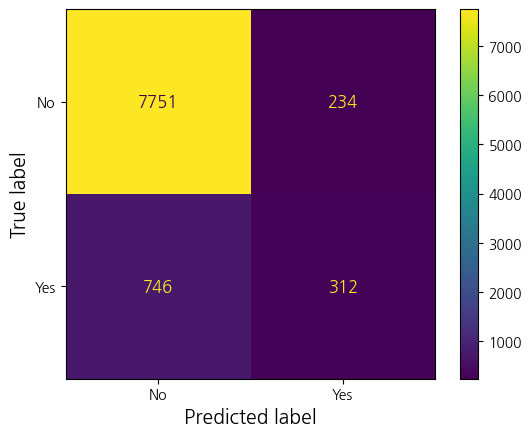

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

test_pred = (
    test_proba >= chosen_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No", "Yes"]
)

plt.show()

### FP와 FN을 따로 살펴본다

테스트 결과에 예측 확률과 오류 유형을 추가한다.

In [27]:
test_results = test_df.copy()

test_results["predicted_probability"] = test_proba
test_results["predicted"] = test_pred

test_results["error_type"] = np.select(
    [
        (test_results["y"] == 1) & (test_results["predicted"] == 1),
        (test_results["y"] == 0) & (test_results["predicted"] == 0),
        (test_results["y"] == 0) & (test_results["predicted"] == 1),
        (test_results["y"] == 1) & (test_results["predicted"] == 0),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN"
    ],
    default="?"
)

test_results["error_type"].value_counts()

,count
error_type,
TN,7751
FN,746
TP,312
FP,234


### 한 조건을 선택해 오류 패턴을 확인한다

`education`, `job`, `housing`, `loan`, `poutcome` 중 하나를 선택한다.

집단별 오분류 비율이 크게 다른지 확인하고, **표본 수가 작은 집단의 비율은 조심해서 해석한다.**

In [31]:
analysis_col = "education"  # TODO: 필요하면 다른 범주형 변수로 변경

error_by_group = pd.crosstab(
    test_results[analysis_col],
    test_results["error_type"],
    normalize="index"
)

group_counts = test_results[analysis_col].value_counts()

error_by_group = (
    error_by_group
    .join(group_counts.rename("count"))
    .sort_values("count", ascending=False)
)

error_by_group

,FN,FP,TN,TP,count
education,,,,,
secondary,0.072829,0.018315,0.880629,0.028227,4641
tertiary,0.101219,0.038788,0.806428,0.053565,2707
primary,0.071970,0.021970,0.891667,0.014394,1320
unknown,0.104000,0.040000,0.810667,0.045333,375


### 오류 사례를 직접 확인한다

모델이 높은 확률로 가입을 예측했지만 실제로 가입하지 않은 FP와, 낮은 확률을 주었지만 실제로 가입한 FN을 살펴본다.

In [29]:
fp_examples = (
    test_results.loc[
        test_results["error_type"] == "FP"
    ]
    .sort_values(
        "predicted_probability",
        ascending=False
    )
    .head(10)
)

fn_examples = (
    test_results.loc[
        test_results["error_type"] == "FN"
    ]
    .sort_values(
        "predicted_probability",
        ascending=True
    )
    .head(10)
)

print("False Positives")
display(fp_examples)

print("False Negatives")
display(fn_examples)

False Positives


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,predicted_probability,predicted,error_type
41580,31,student,single,tertiary,no,64,no,no,cellular,15,sep,208,1,105,2,success,0,0.920619,1,FP
45098,44,technician,single,unknown,no,11115,no,no,cellular,25,oct,189,1,185,4,success,0,0.894581,1,FP
43303,42,management,married,tertiary,no,1205,no,no,telephone,15,mar,129,1,188,2,success,0,0.885247,1,FP
43340,37,technician,married,secondary,no,1458,no,no,cellular,22,mar,344,1,326,1,success,0,0.878069,1,FP
44806,74,retired,divorced,primary,no,2308,no,no,telephone,16,sep,251,2,535,2,success,0,0.878065,1,FP
41659,41,management,divorced,tertiary,no,3426,no,no,cellular,1,oct,302,1,119,5,success,0,0.872157,1,FP
42498,26,services,single,tertiary,no,12,no,no,cellular,15,dec,72,4,186,6,success,0,0.866319,1,FP
43317,32,management,single,tertiary,no,1619,no,no,cellular,17,mar,184,1,321,2,success,0,0.866021,1,FP
44678,60,admin.,married,secondary,no,12980,no,no,cellular,3,sep,177,2,182,1,success,0,0.849105,1,FP
44777,62,admin.,married,secondary,no,4608,no,no,cellular,14,sep,706,1,186,1,success,0,0.844984,1,FP


False Negatives


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,predicted_probability,predicted,error_type
4675,36,blue-collar,married,primary,no,408,yes,yes,unknown,20,may,1063,2,-1,0,unknown,1,0.008514,0,FN
1124,29,management,married,tertiary,no,199,yes,yes,unknown,7,may,1689,4,-1,0,unknown,1,0.012227,0,FN
4753,41,blue-collar,married,primary,no,1250,yes,no,unknown,20,may,1392,2,-1,0,unknown,1,0.012512,0,FN
4035,34,blue-collar,married,primary,no,695,yes,yes,unknown,16,may,1064,4,-1,0,unknown,1,0.012975,0,FN
7480,30,blue-collar,married,secondary,no,486,yes,no,unknown,29,may,1109,3,-1,0,unknown,1,0.013619,0,FN
4455,31,blue-collar,married,secondary,no,2,yes,no,unknown,20,may,182,2,-1,0,unknown,1,0.014136,0,FN
891,53,services,divorced,primary,no,-291,yes,yes,unknown,7,may,591,1,-1,0,unknown,1,0.014261,0,FN
7281,56,technician,married,secondary,no,589,yes,no,unknown,29,may,535,2,-1,0,unknown,1,0.015805,0,FN
4136,47,blue-collar,married,secondary,no,863,yes,no,unknown,19,may,943,2,-1,0,unknown,1,0.016157,0,FN
4509,35,services,married,secondary,no,4170,yes,no,unknown,20,may,1777,1,-1,0,unknown,1,0.016912,0,FN


### 오류 분석 기록

다음을 기록한다.

- 선택한 집단에서 FP 또는 FN 비율이 눈에 띄게 높은 경우가 있는가? : 교육 수준별로 비교했을때 unknown 집단의 FN 비율이 10.4%, FP 비율이 4.0%로 가장 높았다. 그다음으로 tertiary 집단의 FN 비율이 약 10.1%, FP 비율이 약 3.9%로 높았다.
- 표본 수가 충분한가? : 표본 수는 secondary 4,641명, tertiary 2,707명, primary 1,320명, unknown 375명이었다. 집단의 패턴을 살펴볼 수는 있지만, unknown은 다른 집단보다 표본이 적으므로 비율 차이를 조심해서 해석해야 한다. 또한 FP·FN 사례는 각각 10개만 골라 확인했으므로 전체 오류를 대표한다고 보기 어렵다.
- FP 사례에서 반복해서 보이는 특성이 있는가? : 높은 가입 확률로 판단했지만 실제로 가입하지 않은 FP 10개 모두 이전 캠페인의 결과가 success였고, 주택 대출과 개인 대출은 없었다 따라서 이전 캠페인에서 성공했더라도 이번에는 가입하지 않을 수 있음을 확인했다. 다만 이것이 오분류의 원인이라고 단정하지는 않는다.
- FN 사례에서 반복해서 보이는 특성이 있는가? : 낮은 가입 확률로 판단했지만 실제로 가입한 FN 10개 모두 주택 대출이 있었고, 연락 수단이 unknown이며 연락 월은 5월이다 또한 pdays가 -1, previous 가 0으로 이전 캠페인의 연락 이력이 없었다 다만 이것을 FN의 패턴이라고 일반화 하지는 않는다.

- 전체 정밀도·재현율만으로는 놓칠 수 있는 점은 무엇인가? : 전체 정밀도와 재현율만으로는 교육 수준 등 고객 집단별 오류 분포의 차이를 알기 어렵다. 집단별 분석과 개별 사례 확인을 통해 어떤 고객에게 오류가 발생하는지 더 구체적으로 살펴볼 수 있었다. 다만 집단별 가입 고객 비율과 표본 수가 다르므로, 오류 비율만으로 특정 집단의 예측 성능이 더 나쁘다고 단정하지 않았다.

> 관찰된 패턴만으로 오류의 원인을 단정하지 않는다.

### 예측 관계와 인과관계를 구분한다

예를 들어 특정 직업이나 교육 수준이 가입 여부 예측에 유용하다고 해서,

> “그 특성이 정기예금 가입을 **원인으로 만들어낸다**”

고 말할 수는 없다.

이번 프로젝트는 관찰 데이터에 기반한 **예측 문제**이며, 변수 간의 인과관계를 확인하는 분석이 아니다.

### 실제 활용에서는 추가 판단이 필요하다

모델이 좋은 성능을 보이더라도 바로 실제 고객 선정에 사용하면 안 된다.

다음을 추가로 검토해야 한다.

- 다른 시기와 다른 캠페인에서도 성능이 유지되는가? : 다른 시기의 고객에게도 비슷한 성능이 나오는지는 추가로 확인해봐야 할 사항이다.
- 고객 구성이나 마케팅 방식이 바뀌면 성능이 달라지는가? : 기존에 학습한 관계가 그대로 적용되지 않을 수도 있다.
- 선택한 임곗값이 실제 연락 비용과 목표에 맞는가? : 현장에서 적합한지는 별도로 검토해야 한다고 판단한다.
- 특정 고객 집단에서 오류가 지나치게 크지 않은가? : 위에서 다룬 교육 수준별 분석처럼 집단별 오류 분석을 통해 확인해야한다.
- 개인정보, 공정성, 관련 규정을 고려했는가? : 고객 정보 사용 가능 유무나 실제 적용에 필요한 규정을 지키는지 추가적으로 검토해야 한다.

### AI 체크포인트 ③ — 결과 해석 검토

최종 결과와 오류 분석을 AI에게 보여 주고 결론 초안을 검토받아도 된다.

다음은 직접 확인한다.

- 테스트 결과를 보고 임곗값을 다시 바꾸지 않았는가? : 0.35을 계속 유지했으므로 충족한다.
- 높은 ROC-AUC를 모든 상황에서 좋은 성능이라고 단정하지 않았는가? : 모든 상황에서 성능이 좋다고 단정하지 않았고 다른 시기의 성능은 추가 검토가 필요하다고 판단하였다.
- 예측 관계를 인과관계로 바꾸지 않았는가? : 가입이나 오류의 원인으로 단정하지 않았다.
- 특정 집단의 작은 표본에서 나타난 차이를 과도하게 일반화하지 않았는가? : unknown 집단과 극단적인 FP FN 각 10개를 과도하게 일반화하지 않도록 주의했다.
- `duration`을 다시 실제 입력 변수처럼 해석하지 않았는가? : 결과 표에 남아 있는 것과 모델 입력에 사용하는 것을 구분했다.

**수정하거나 받아들이지 않은 AI의 제안과 그 이유**

> 작성: AI가 나이를 연령대별 범주로 나누어 입력 변수로 사용하는 방법을 제안했지만, 이번 기본 분석에서는 나이를 수치형으로 사용하므로 해당 제안은 적용하지 않았다. 연령대 구분은 EDA에서 가입률을 비교하는 용도로만 사용했다. 또한 교육 수준별 오류 비율을 해석할 때, 집단 전체 대비 FN·FP 비율만으로 특정 집단의 예측 성능이 더 나쁘다고 단정하지 않도록 해석을 수정했다.

### 최종 결론을 작성한다

다음 내용을 포함한다.

- **분석 질문에 대한 답**
- **`duration`을 제외한 이유**
- **로지스틱 회귀와 기준선의 차이**
- **선택한 결정 임곗값과 선택 근거**
- **정밀도·재현율·ROC-AUC의 의미**
- **FP와 FN 중 더 중요하게 판단한 오류**
- **오류 분석에서 발견한 점**
- **실제 활용 가능성**
- **분석의 한계 두 가지 이상**
- **다음 분석에서 추가할 정보 또는 방법**


이번 분석에서 전화 통화 시작 직전에 알 수 있는 고객 정보와 과거 마케팅 이력을 이용해 정기예금 가입 여부를 예측했다. EDA에서 60세 이상과 30세 미만의 가입률이 상대적으로 높았고, 교육 수준과 신용 채무 불이행 여부에 따라서도 가입률 차이가 관찰되었다. 이러한 정보는 가입 여부 예측에 유용할 수 있다고 판단했다. 다만 이것이 가입의 원인을 뜻하는 것은 아니다.

duration은 통화 이후에 알 수 있는 정보이므로 최종 모델에서 제외하였다. 이는 통화 직전에는 사용할 수 없는 정보이므로 데이터 누수가 발생한다는 점에서 제외하기로 판단했다.

기준선은 모든 고객을 미가입으로 예측하여 정확도는 88.3%였지만 가입 고객은 한명도 찾아내지 못했다. 로지스틱 회귀는 검증 데이터에서 임곗값 0.5에서 정확도 약 89.5%와 재현율 약 19.5% ROC-AUC 약 0.777을 보여 기준선보다 가입 고객을 구분하는 능력이 개선되었음을 알 수 있다.

결정 임곗값은 0.35로 선택했다. 이유는 실제로 가입하지 않을 고객에게 연락하여 인력과 시간이 소모되는 것을 줄이기 위해 FN보다 FP를 줄이는 것을 더 중요하게 판단했다. 따라서 제한된 마케팅 인력과 시간을 효율적으로 사용하기 위하여 재현율보다는 정밀도를 우선시 하였다. 다만 가입 고객을 지나치게 놓치지 않도록 재현율을 최소 30%는 확보하고자 하였고 이 조건중에서 제일 정밀도가 높은 임곗값을 선택하였다.

정밀도는 모델이 가입한다고 예측한 고객 중 실제로 가입한 고객의 비율이다.
재현율은 실제 가입 고객 중 가입한다고 올바르게 예측한 고객의 비율이다.
ROC-AUC는 여러 임곗값에서 모델이 가입고객과 미가입 고객을 얼마나 잘 구분하는지 나타내는 지표이며 1에 가까울 수록 구분 능력이 좋고 0.5는 무작위 예측 수준으로 본다. 최종 테스트에서는 정밀도 약 57.1%, 재현율 약 29.5%, ROC-AUC 약 0.774로 검증 결과와 유사한 성능을 보였다. 다만 실제 가입 고객의 약 70.5%를 놓친다는 한계가 있었다.

오류 분석에서 높은 가입 확률을 부여했지만 실제로 가입하지 않은 FP 10개 모두 이전의 캠페인의 결과가 success였고 주택 대출과 개인 대출이 없었다. 반대로 낮은 가입 확률을 부여했지만 실제로 가입한 FN 10개 모두 주택 대출이 있었으며, 연락 수단은 unknown, 연락 월은 5월이었다. 다만 이 오류 사례를 전체 오류의 특성으로 일반화 하지는 않는다.

이 모델을 실제 활용한다면 가입 가능성을 바탕으로 고객 연락 우선순위를 정하는데에 활용할 수 있다. 다만 다른 시기나 캠페인에서도 같은 성능이 유지되는지는 확인하지 않았고 실제의 연락 비용이나 인력, 시간 비용을 반영해서 임곗값을 선택한 것은 아니므로 이 모델을 실제에 활용하기에는 충분히 적절하지는 않다고 판단한다.

그렇기에 다음 분석에서 추가할 정보로 실제 연락비용과 가입 수익 정보를 추가해서 임곗값을 검토하고 다른 시기나 캠페인의 데이터로 성능을 추가로 평가한다.

### 프로젝트 최종 제출 전 확인

- [ ] 타깃, 양성 클래스와 예측 시점을 설명했다.
- [ ] 최종 테스트셋을 모델·임곗값 선택에 사용하지 않았다.
- [ ] `duration`이 데이터 누수인 이유를 설명했다.
- [ ] 범주형 변수에 원-핫 인코딩을 적용했다.
- [ ] 기준선과 로지스틱 회귀를 비교했다.
- [ ] 정확도, 정밀도, 재현율, ROC-AUC를 해석했다.
- [ ] 결정 임곗값을 검증 데이터에서 선택하고 근거를 적었다.
- [ ] 최종 테스트셋에서 선택한 임곗값을 그대로 사용했다.
- [ ] FP와 FN을 실제 문제의 관점에서 해석했다.
- [ ] 오류 분석과 분석의 한계를 적었다.
- [ ] AI의 제안을 검토한 근거를 남겼다.

### 평가 기준

| 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제와 데이터 이해 | 4 | 타깃·양성 클래스·예측 시점·데이터 누수를 적절히 설명했는가? |
| 분석 방법 | 4 | 데이터 분할·전처리·기준선·로지스틱 회귀의 절차가 타당한가? |
| 평가와 임곗값 판단 | 5 | 정확도·정밀도·재현율·ROC-AUC를 구분하고 임곗값 선택에 자신의 근거가 있는가? |
| 결과 해석 | 4 | 최종 성능과 FP·FN 및 조건별 오류를 현실의 언어로 정확히 해석했는가? |
| 검증과 한계 | 3 | 테스트셋 보존, AI 결과 검토, 일반화와 한계를 적절히 다루었는가? |
| **합계** | **20** | |